# CAMELYON17 — Comparaison multicentres

Cette étude complémentaire utilise les patchs du prototype. Ses scores décrivent cette expérience et son échantillon de 14 lames.

Étude exploratoire sur 14 lames de 14 patientes distinctes. Ce notebook lit les résultats enregistrés, recalcule les métriques et affiche les figures. Il ne modifie aucun modèle ni seuil. Le protocole de calcul est conservé dans `reproduction/03_multicentres_calcul.ipynb`.

## 1. Protocole
Six lames d’entraînement et quatre de validation proviennent des centres 0 et 4. Quatre lames du centre 2 sont réservées au test de la méthode choisie. La réserve a désormais été évaluée : toute amélioration guidée par ce résultat devra être déclarée exploratoire ou évaluée sur une nouvelle réserve.

Les patchs de 224 × 224 pixels sont lus au niveau 1, sur une grille sans chevauchement. La résolution effective est de 0,486 µm/pixel dans le centre 0, de 0,500 dans le centre 4 et de 0,452 à 0,454 dans le centre 2. Le niveau numérique identique ne garantit pas un champ physique identique. Les quotas de patchs et le choix de petites lames limitent la représentativité.

Consulter `../README.md` pour les installations et les données nécessaires, puis `../docs/CHOIX_ET_JUSTIFICATIONS.md` pour comprendre les choix. Le notebook de synthèse et les figures sont utilisables sans les images originales.


## Repères pour comprendre

| Terme | Sens dans ces notebooks |
|---|---|
| Patch | Petite image de 224 × 224 pixels extraite d’une lame |
| Score | Nombre produit par le modèle entre 0 et 1 ; ce n’est pas une certitude médicale |
| Seuil | À partir de cette valeur, le patch est classé tumoral |
| VP / FN | Tumeur détectée / tumeur manquée |
| VN / FP | Sain correctement classé / fausse alerte |
| Rappel | VP ÷ (VP + FN) : part des patchs tumoraux détectés |
| Précision | VP ÷ (VP + FP) : part des alertes qui correspondent à une tumeur |
| Spécificité | VN ÷ (VN + FP) : part des patchs sains correctement classés |

Ce notebook présente les résultats déjà calculés. Le code complet et commenté se trouve dans `reproduction/`. Les résultats concernent des patchs sélectionnés et ne suffisent pas à valider le stade pN d’une patiente.


In [4]:
# Lecture des résultats enregistrés : aucun entraînement et aucun changement de seuil.
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Le terminal peut être placé à la racine du dépôt ou dans ce dossier.
ROOT = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    for candidat in [parent, parent / "analyses/multicentres"]:
        if (candidat / "resultats/multicentres/choix_final.json").is_file():
            ROOT = candidat
            break
    if ROOT is not None:
        break
if ROOT is None:
    raise FileNotFoundError("Ouvrir ce notebook dans le dépôt contenant analyses/multicentres.")
EXP = ROOT / 'resultats/multicentres'
sys.path.insert(0, str(ROOT / 'scripts'))
from verifier_resultats import verifier
display(pd.DataFrame(verifier(ROOT), columns=['Contrôle', 'Résultat']))
choix = json.loads((EXP / 'choix_final.json').read_text())
selection = pd.read_csv(EXP / 'selection.csv')
display(selection[['ensemble', 'centre', 'patiente', 'lame', 'classe']])


,Contrôle,Résultat
0,Identifiant de configuration,OK
1,"Cohorte, effectifs, partitions et absence de c...",OK
2,"original : mêmes exemples, scores, C, seuil, m...",OK
3,"reinhard : mêmes exemples, scores, C, seuil, m...",OK
4,"macenko : mêmes exemples, scores, C, seuil, mé...",OK
5,Choix final conforme à la règle de validation,OK
6,Métriques du test globales et par lame,OK


,ensemble,centre,patiente,lame,classe
0,train,4,patient_083,patient_083_node_4,negative
1,train,4,patient_089,patient_089_node_3,micro
2,train,4,patient_096,patient_096_node_0,macro
3,train,0,patient_005,patient_005_node_0,negative
4,train,0,patient_012,patient_012_node_0,macro
5,train,0,patient_010,patient_010_node_4,micro
6,validation,4,patient_092,patient_092_node_1,macro
7,validation,4,patient_086,patient_086_node_2,negative
8,validation,0,patient_015,patient_015_node_1,macro
9,validation,0,patient_000,patient_000_node_4,negative


## 2. Préparation et modèle
Un patch est positif si son carré central de 112 pixels contient au moins un pixel tumoral. Un patch négatif ne contient aucun pixel tumoral ; les cas avec tumeur uniquement périphérique sont exclus. Au moins 25 % des pixels doivent dépasser une saturation HSV de 0,04. Les régions transparentes sont exclues.

Effectifs : 1 325 patchs d’entraînement (525 positifs), 1 000 de validation (400 positifs), 864 de test (264 positifs). Les deux lames micro d’entraînement apportent 120 et 5 patchs positifs. Il n’y a aucune lame micro en validation.

ResNet18 ImageNet reste fixe ; StandardScaler et régression logistique L2 sont ajustés pour chaque condition. C est choisi parmi cinq valeurs selon l’AUC moyenne des centres de validation. La référence de normalisation est une mosaïque de 16 patchs d’entraînement. Les trois méthodes utilisent les mêmes patchs.

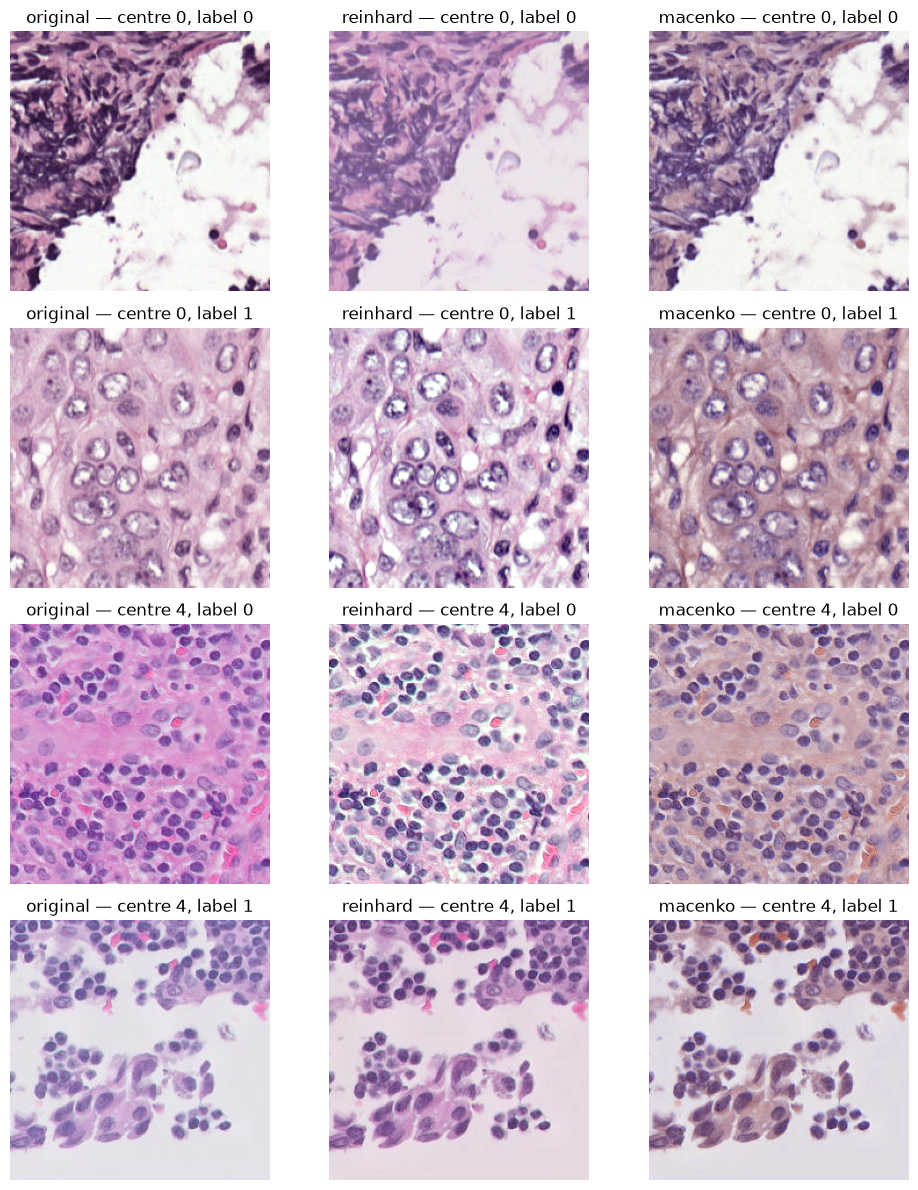

## 3. Sélection sur la validation
Un seuil unique par méthode respecte au moins 95 % de rappel dans chacun des deux centres. Parmi les méthodes admissibles, la spécificité moyenne par centre détermine le choix, puis l’AUC départage les ex æquo. Les fichiers `_recalibre` sont les résultats de référence ; les premiers seuils globaux sont conservés uniquement pour la traçabilité. Le recalibrage a été effectué avant le test.

Les images originales sont retenues : 62 fausses alertes, contre 75 pour Reinhard et 107 pour Macenko. Elles ont aussi davantage de faux négatifs (17 contre 16 et 14) ; le choix correspond donc au compromis annoncé, pas à une supériorité sur toutes les métriques.

,methode,centre,seuil,n,VP,VN,FP,FN,rappel,precision,specificite,auc
0,original,0,0.3139,500,193,247,53,7,0.965,0.7846,0.8233,0.9632
1,original,4,0.3139,500,190,291,9,10,0.950,0.9548,0.9700,0.9871
2,reinhard,0,0.2526,500,194,236,64,6,0.970,0.7519,0.7867,0.9649
3,reinhard,4,0.2526,500,190,289,11,10,0.950,0.9453,0.9633,0.9884
4,macenko,0,0.2437,500,196,207,93,4,0.980,0.6782,0.6900,0.9606
5,macenko,4,0.2437,500,190,286,14,10,0.950,0.9314,0.9533,0.9880


,methode,C,seuil,FP,FN,specificite_moyenne,auc_moyenne,temps_mesure_s
0,original,0.001,0.3139,62,17,0.8967,0.9752,78.2260
1,reinhard,0.001,0.2526,75,16,0.8750,0.9767,121.9004
2,macenko,0.001,0.2437,107,14,0.8217,0.9743,111.8990


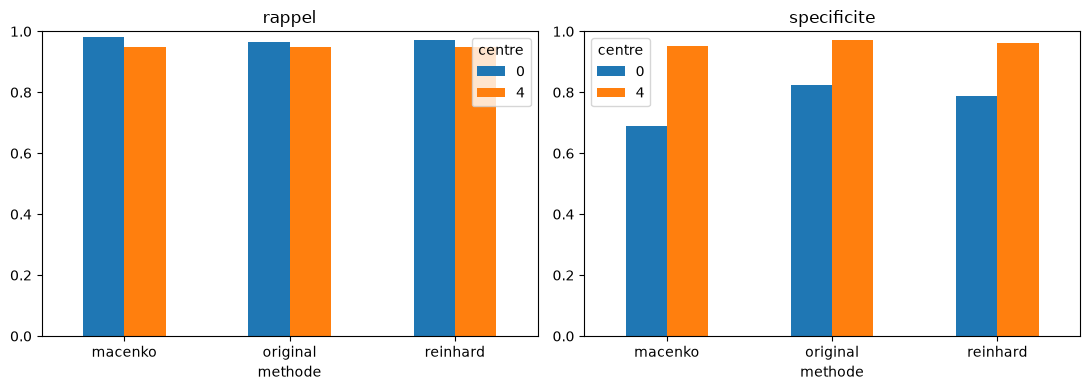

In [5]:
# Lecture des résultats enregistrés : aucun entraînement et aucun changement de seuil.
validation = pd.read_csv(EXP / 'metriques_validation_par_centre_recalibre.csv')
comparaison = pd.read_csv(EXP / 'comparaison_methodes_recalibre.csv')
display(validation.round(4))
display(comparaison[['methode',
    'C',
    'seuil',
    'FP',
    'FN',
    'specificite_moyenne',
    'auc_moyenne',
    'temps_mesure_s']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, mesure in zip(axes, ['rappel', 'specificite']):
    validation.pivot(index='methode',
        columns='centre',
        values=mesure).plot.bar(ax=ax,
        ylim=(0,
        1),
        rot=0,
        title=mesure)
fig.tight_layout()
plt.show()


Les temps de développement couvrent la normalisation et le CNN sur les 2 325 patchs : 78,23 s pour original, 121,90 s pour Reinhard, 111,90 s pour Macenko. Ils excluent le téléchargement, la lecture disque, l’extraction des patchs, la préparation des tenseurs et la régression logistique. Ce sont des mesures uniques sur CPU. Aucun repli vers les images originales n’a été journalisé pour les normalisations.

## 4. Test du centre 2
Configuration figée : images originales, C = 0,001, seuil = 0,31390092. Les autres méthodes ne sont pas comparées sur ce test pour choisir une nouvelle gagnante.

In [6]:
# Lecture des résultats enregistrés : aucun entraînement et aucun changement de seuil.
test = pd.read_csv(EXP / 'metriques_test.csv')
par_lame = pd.read_csv(EXP / 'metriques_test_par_lame.csv')
display(test.round(4))
display(par_lame.round(4))
temps = pd.read_csv(EXP / 'temps_test_original.csv')
print('Normalisation et CNN du test :',
    round(float(temps.normalisation_s.sum() + temps.cnn_s.sum()),
    2),
    'secondes')


,methode,centre,seuil,replis,regression_prediction_s,n,VP,VN,FP,FN,rappel,precision,specificite,auc
0,original,2,0.3139,0,0.0157,864,172,589,11,92,0.6515,0.9399,0.9817,0.8715


,lame,n,VP,VN,FP,FN,rappel,precision,specificite,auc
0,patient_044_node_4,300,172,98,2,28,0.86,0.9885,0.980,0.9822
1,patient_046_node_4,164,0,100,0,64,0.00,NaN,1.000,0.5370
2,patient_055_node_0,200,0,195,5,0,NaN,0.0000,0.975,NaN
3,patient_059_node_4,200,0,196,4,0,NaN,0.0000,0.980,NaN


Normalisation et CNN du test : 24.06 secondes


Sur les 864 patchs : VP 172, FN 92, FP 11, VN 589. Rappel 65,2 %, précision 94,0 %, spécificité 98,2 %, AUC 0,8715. La lame macro a 172 patchs positifs détectés sur 200 ; la lame micro en a 0 sur 64. Le rappel n’est pas défini pour les lames sans positif et l’AUC n’est pas définie lorsqu’une seule classe est présente : les valeurs manquantes correspondantes sont attendues.

La faible AUC de la lame micro (0,5370) indique que ses scores séparent peu les classes. La baisse ne peut pas être attribuée uniquement à l’hôpital : type de lésion, faible diversité des cas, échantillonnage et résolution physique diffèrent également.

## 5. Analyse descriptive des faux négatifs
Six exemples de la lame micro sont sélectionnés à différents rangs de score. Les zones annotées représentent 11,2 à 32,7 % du patch et sont parfois proches du bord de la zone centrale. Même l’exemple à 32,7 % reçoit un score de 0,041. La faible proportion tumorale est une hypothèse contributive, pas une cause démontrée. Le rouge est l’annotation de référence ; le cyan représente la zone d’étiquetage. Cette figure n’est pas une carte d’explication du modèle.

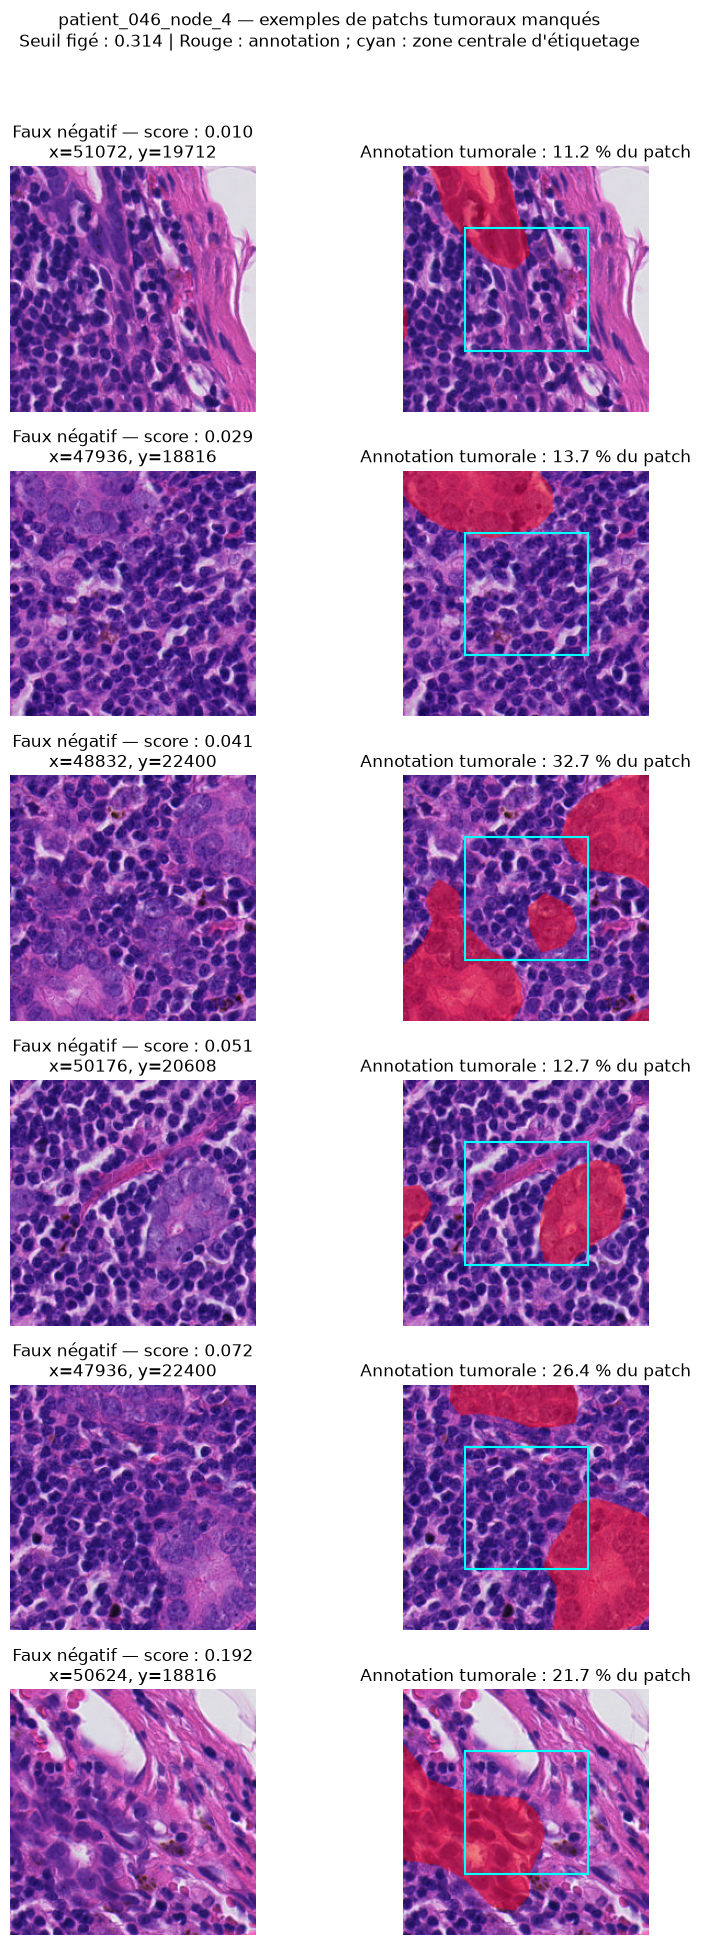

## 6. Conclusion et limites
L’étude compare effectivement deux normalisations et les images originales dans un protocole commun. La condition originale satisfait la règle de sélection sur la validation avec le moins de fausses alertes. La généralisation au centre 2 est insuffisante pour la contrainte de rappel visée, en particulier sur l’unique lame micro du test.

Les 14 patientes, les quotas, la validation sans micrométastase, l’absence d’ITC et la référence unique de normalisation limitent les conclusions. Des milliers de patchs ne constituent pas des milliers de cas indépendants. Aucun gain général de normalisation ni équité entre centres n’est établi.

L’expérience ne produit pas de cartes exhaustives, de classes de lames ni de pN.